In [3]:
import matplotlib.pyplot as plt
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import transforms
from torchvision import models

from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


Пока я читал статью $Gatys \space et\space al.\space 2016$ про нейронный перенос стиля, там возникает утверждение о том, что можно получать из feature map сверточного слоя (иначе говоря, выход сверточного слоя по входу изображения) приближение к исходному изображению. Далее есть ссылка на статью про image representation, где изучается анализ восстановления изображения по CNN выходу.

Все это говорит о том, что правильно обученная CNN позволяет вытаскивать из изображения важные черты, которые помогают его распознавать. Это наталкивает на мысли о реализации переноса стиля: берем зашумленную картинку, а далее, суммируя лоссы для близости с контентом и близости со стилем, делаем оптимизацию. Только пока непонятно, какими должны быть лоссы, но с этим разберемся потом.

Первая цель здесь - взять VGG-19 и попробовать посмотреть, какое качество восстановления изображения возможно.

In [2]:
vgg19 = models.vgg19(pretrained=True)
vgg19

d:\Учеба\Анализ данных\hw5\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
d:\Учеба\Анализ данных\hw5\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG19_Weights.IMAGENET1K_V1`. You can also use `weights=VGG19_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padd

Буду пробовать на своем тестовом изображении. Используем из VGG только feature extractor. Как видим, сверточные слои имеют очень много каналов по ходу углубления сети. Прежде нужно немного обработать изображение для подачи. Хочется сделать поменьше разрешения для оптимизации работы. VGG заточена на размер 224x224, такой и сделаю. Кроме того, сети нужна своя нормализация изображения.

In [4]:
my_img = Image.open("reconstruction_src/my_img.jpg").convert("RGB")

work_transform = transforms.Compose(
    [
        transforms.Resize(224,
                          interpolation=transforms.InterpolationMode.LANCZOS),
        transforms.ToTensor(),
    ]
)

work_img = work_transform(my_img)

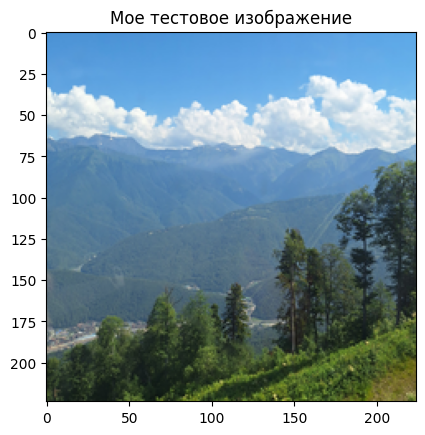

In [5]:
plt.Figure(figsize=(12, 12))

plt.imshow(work_img.permute(1, 2, 0))

plt.title("Мое тестовое изображение")
plt.show()

In [5]:
feature_extractor = vgg19.features.to(device)
feature_extractor

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (17): ReLU(inplace=True)
  (18): MaxPoo

Посмотрим на выходы сверточных слоев сети для нормализованного изображения. Непонятно, как это изображать в цветном варианте, так что выводим, как есть.

In [6]:
mean_normalization = [0.485, 0.456, 0.406]
std_normalization = [0.229, 0.224, 0.225]
normalized_img = transforms.Normalize(mean=mean_normalization, std=std_normalization)(work_img).to(device)

outputs = []
prev_output = normalized_img.clone()

for stage in feature_extractor:
    prev_output = stage(prev_output)
    outputs.append(prev_output.clone())

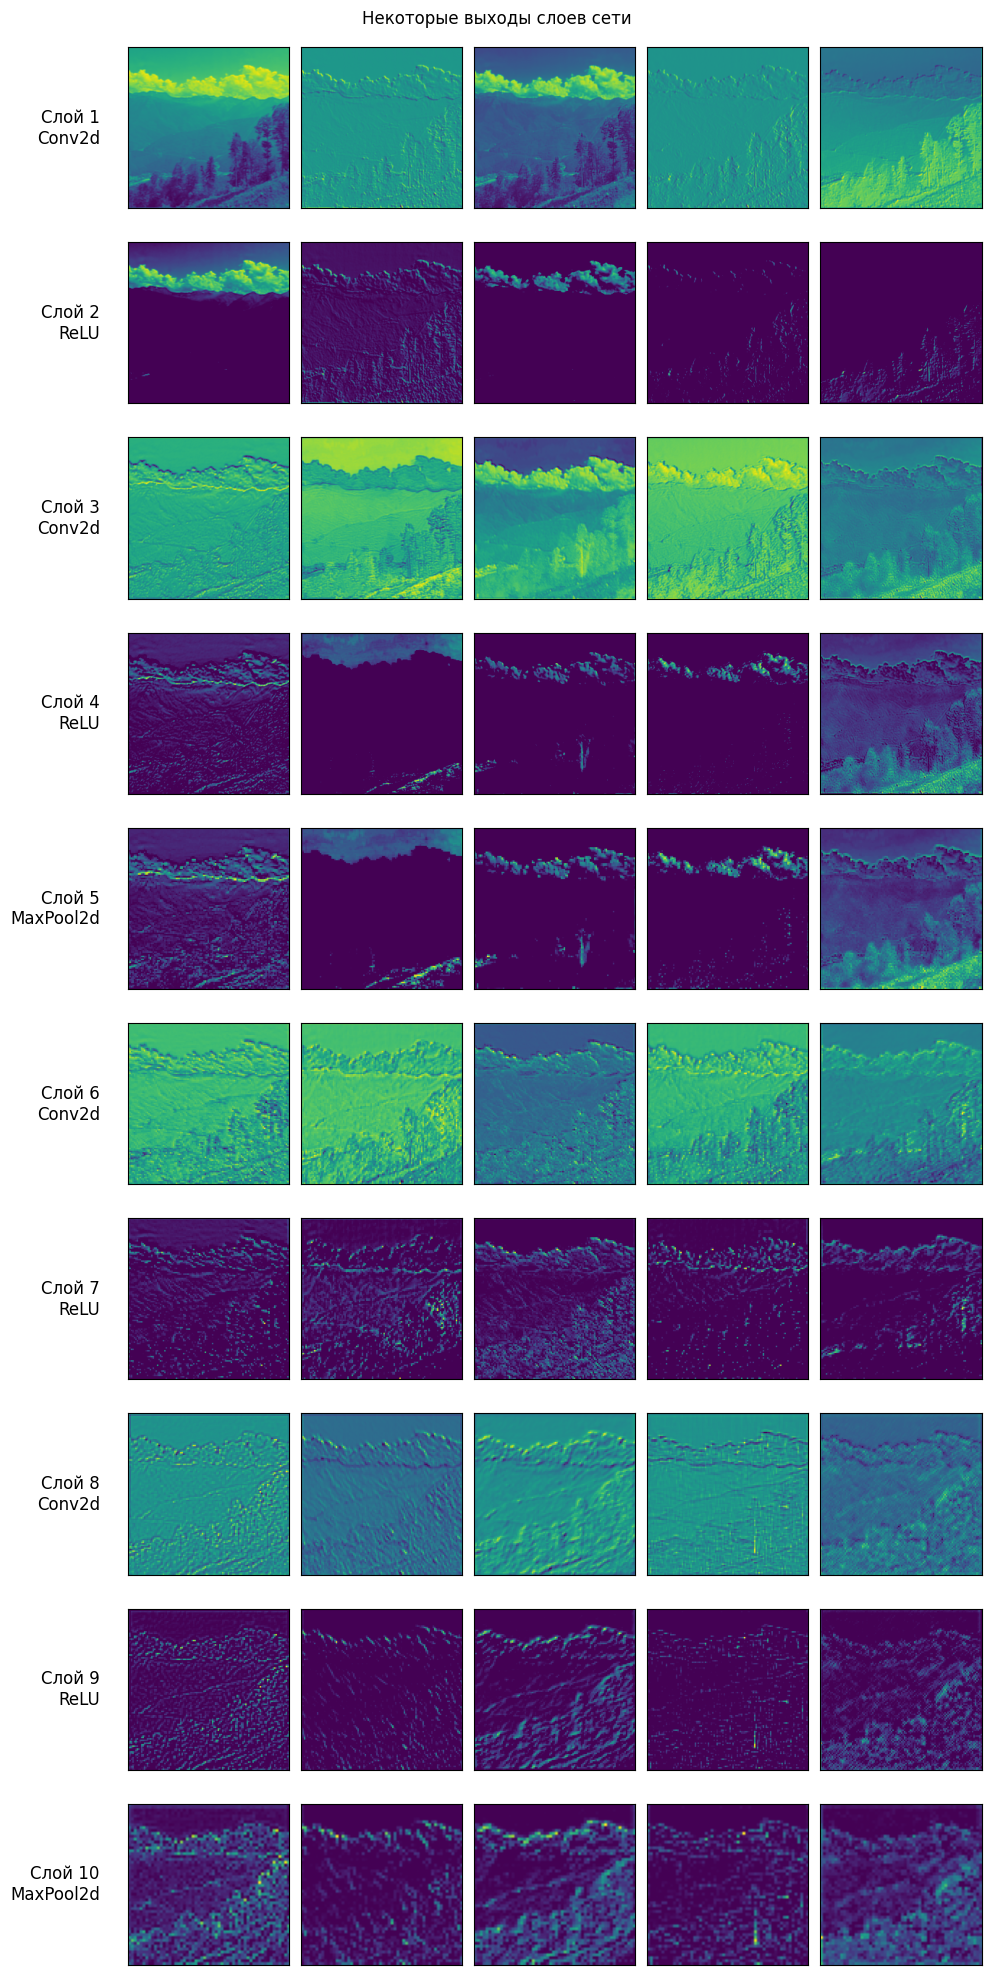

In [7]:
count_layers = 10
count_kernels = 5

fig, axes = plt.subplots(count_layers, count_kernels, figsize=(10, 20))

for layer in range(count_layers):
    axes[layer][0].set_ylabel(
        f"Слой {layer + 1}\n{feature_extractor[layer].__class__.__name__}",
        rotation=0,
        size='large',
        ha='right',
        va='center',
        labelpad=20
    )

    for kernel in range(count_kernels):
        axes[layer][kernel].imshow(outputs[layer][kernel].detach().cpu())
        
        axes[layer][kernel].set_xticks([])
        axes[layer][kernel].set_yticks([])

plt.suptitle('Некоторые выходы слоев сети', y=0.99)
plt.tight_layout()
plt.show()

Довольно прикольные картинки. Видим, что на них выделяются контуры изображения. На основе таких картинок (из самого глубокого слоя) классификатор VGG в конце принимает решение о классе изображения. Посмотрим на картинки из самого глубого слоя.

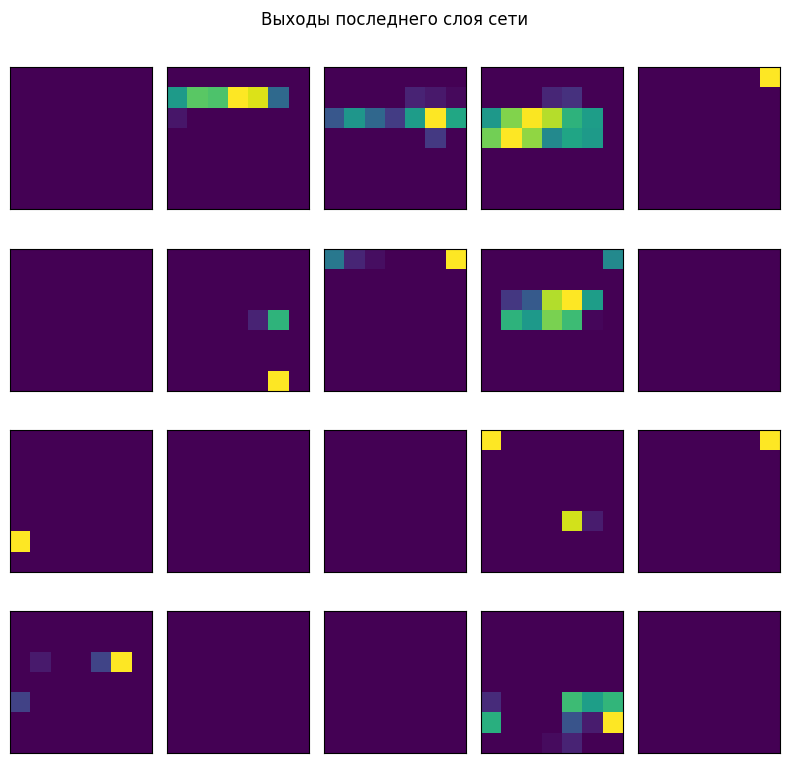

In [8]:
fig, axes = plt.subplots(4, 5, figsize=(8, 8))
axes = axes.flatten()

for i in range(len(axes)):
    axes[i].imshow(outputs[-1][i].detach().cpu())
    
    axes[i].set_xticks([])
    axes[i].set_yticks([])

plt.suptitle("Выходы последнего слоя сети")
plt.tight_layout()
plt.show()

Сложно представить, что на основе таких картинок классификатор делает вывод. По ним уже очень сложно понять, каким было изображение изначально.

Теперь попробуем восстановление исходного изображения по выходу сверточного слоя. Обозначим за $\vec{x}$ наше исходное изображение, $\phi_l$ - преобразование сети, включающее $l$-й сверточный слой сети. Таким образом, $\phi_l(\vec{x})$ есть результат применения $l$-го сверточного слоя к нашему исходному изображению. Хотим как бы обратное преобразование.

Какой подход? Будем делать градиентный спуск по $\vec{p}$, минимизируя лосс $\|\phi_l(\vec{x}) - \phi_l(\vec{p})\|_2^2$. Так можно делать, поскольку CNN дифференцируема по своим входам (это нужно доказывать, основной интерес для меня составляет ситуация с max pooling слоем). Понятно, что в этой задаче минимизации точка глобального минимума есть, и это $\vec{x}$. Однако, он будет не единственным. Дело в том, что мы применяем нелинейность в виде ReLU на каждом сверточном слое, так что в качестве оптимума интуитивно будет подходит не одно исходное изображение. Пробуем делать для разных слоев. Такой подход восстановления изображения сразу пришел мне в голову. Посмотрим, что из него выйдет.

In [7]:
conv_indexes = []
conv_indexes.append([])
for layer in enumerate(feature_extractor):
    if str(layer[1])[:3] == "Max":
        conv_indexes.append([])
        continue
    if str(layer[1])[:4] == "Conv":
        conv_indexes[-1].append(layer[0])
conv_indexes = conv_indexes[:-1]
conv_indexes

[[0, 2], [5, 7], [10, 12, 14, 16], [19, 21, 23, 25], [28, 30, 32, 34]]

Первоначально инициализируем $\vec{p}$ нормальным шумом. Далее по заданному выше плану. Стоит заметить, что я использую восстанавление нормализованного изображения, так как на нормализованные таким образом изображения заточена VGG.

In [ ]:
def denormalization(image: torch.tensor):
        mean = torch.tensor(mean_normalization, device=device).view(3, 1, 1)
        std = torch.tensor(std_normalization, device=device).view(3, 1, 1)

        return (image * std + mean).clamp(0, 1)

def reconstruct_image(
        image : torch.Tensor,
        index_deep: int,
        index_conv: int,
        learning_rate: float = 1,
        steps: int = 1000,
        device: str = 'cpu'
) -> torch.tensor:

        index_layer = conv_indexes[index_deep][index_conv]
        part_model = feature_extractor[:index_layer + 1].to(device).eval()

        p = torch.randn((1, 3, image.shape[1], image.shape[2]), requires_grad=True, device=device)
        optimizer = optim.Adam([p], lr=learning_rate)

        target_map = part_model(image.to(device)).detach().to(device)

        for i in range(steps):
                feature_map = part_model(p)
                loss = ((target_map - feature_map)**2).mean()

                # Логирование лосса
                if (i + 1) % 20 == 0:
                        print(f'Шаг {i + 1}, loss = {loss}')

                loss.backward()
                optimizer.step()
                optimizer.zero_grad()
        
        return p.squeeze(0).detach()

# update with lbfgs
def reconstruct_image_lbfgs(
        image : torch.Tensor,
        index_deep: int,
        index_conv: int,
        learning_rate: float = 1,
        steps: int = 1000,
        device: str = 'cpu'
) -> torch.tensor:

        index_layer = conv_indexes[index_deep][index_conv]
        part_model = feature_extractor[:index_layer + 1].to(device).eval()

        p = torch.randn((1, 3, image.shape[1], image.shape[2]), requires_grad=True, device=device)
        optimizer = optim.LBFGS([p], 
                                lr=learning_rate,
                                line_search_fn='strong_wolfe'
                                )

        target_map = part_model(image.to(device)).detach().to(device)

        for i in range(steps):
                def closure():
                        optimizer.zero_grad()
                        feature_map = part_model(p)
                        loss = ((target_map - feature_map)**2).mean()

                        loss.backward()
                        return loss

                loss = optimizer.step(closure)

                # Логирование лосса
                # if (i + 1) % 20 == 0:
                print(f'Шаг {i + 1}, loss = {loss}')

        return denormalization(p.squeeze(0).detach())

Посмотрим, что выходит для первого сверточного слоя.

In [11]:
def plot_reconstruction(result : torch.tensor, deep : int):

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    axes[0].imshow(denormalization(result).permute(1, 2, 0).cpu())
    axes[0].set_xticks([])
    axes[0].set_yticks([])
    axes[0].set_title(f'Восстановленное изображение с глубины {deep}')

    axes[1].imshow(work_img.permute(1, 2, 0).cpu())
    axes[1].set_xticks([])
    axes[1].set_yticks([])
    axes[1].set_title("Исходное изображение")

    plt.show()

Шаг 20, loss = 0.12168501317501068
Шаг 40, loss = 0.015425258316099644
Шаг 60, loss = 0.002207490149885416
Шаг 80, loss = 0.00030038508703000844
Шаг 100, loss = 4.18406052631326e-05


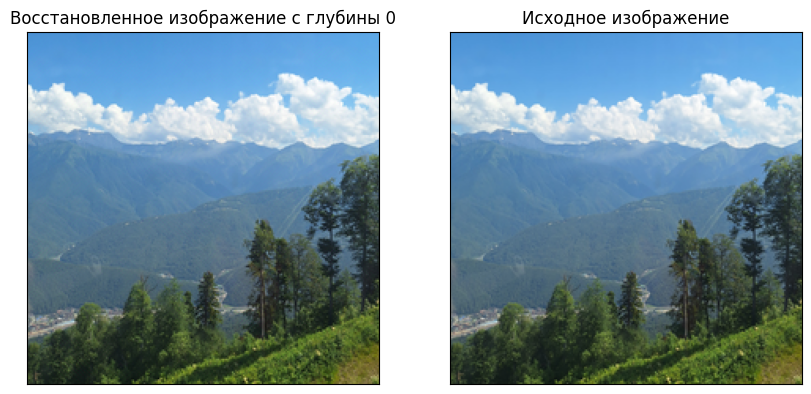

In [12]:
deep = 0
reconstruction_conv_0 = reconstruct_image(normalized_img, deep, 0, 1, 100, device)

plot_reconstruction(reconstruction_conv_0, deep)

Как видим, полученное изображение визуально точь-в-точь с исходным. Глобальный минимум был найден. Теперь посмотрим на реконструкции со сверточных слоев каждой глубины.

Шаг 20, loss = 4.961029052734375
Шаг 40, loss = 1.119315505027771
Шаг 60, loss = 0.39368414878845215
Шаг 80, loss = 0.23318757116794586
Шаг 100, loss = 0.17580696940422058
Шаг 120, loss = 0.14386652410030365
Шаг 140, loss = 0.12152350693941116
Шаг 160, loss = 0.10449952632188797
Шаг 180, loss = 0.09091383963823318
Шаг 200, loss = 0.07987890392541885
Шаг 220, loss = 0.07105667889118195
Шаг 240, loss = 0.06531816720962524


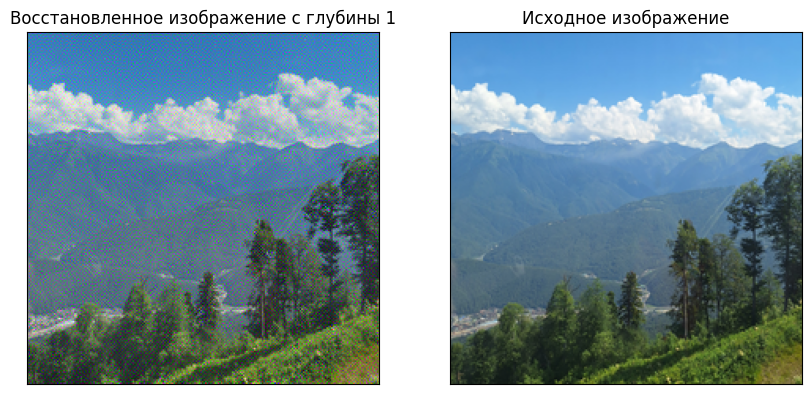

In [13]:
deep = 1
reconstruction_conv_1 = reconstruct_image(normalized_img, deep, 0, 0.5, 250, device)

plot_reconstruction(reconstruction_conv_1, deep)

По содержанию картинка была полностью восстановлена, однако поверх появился шум.

Шаг 20, loss = 19.1466007232666
Шаг 40, loss = 8.270116806030273
Шаг 60, loss = 4.6194071769714355
Шаг 80, loss = 3.0827479362487793
Шаг 100, loss = 2.289318323135376
Шаг 120, loss = 1.8173696994781494
Шаг 140, loss = 1.512169599533081
Шаг 160, loss = 1.3087353706359863
Шаг 180, loss = 1.1642191410064697
Шаг 200, loss = 1.0551190376281738
Шаг 220, loss = 0.9682821035385132
Шаг 240, loss = 0.8996800780296326
Шаг 260, loss = 0.8385869860649109
Шаг 280, loss = 0.7878242135047913
Шаг 300, loss = 0.7437978386878967
Шаг 320, loss = 0.6990653872489929
Шаг 340, loss = 0.6624022126197815
Шаг 360, loss = 0.6337611675262451
Шаг 380, loss = 0.613355815410614
Шаг 400, loss = 0.6021870374679565
Шаг 420, loss = 0.6370279788970947
Шаг 440, loss = 0.6613718867301941
Шаг 460, loss = 0.5848421454429626
Шаг 480, loss = 0.5528196096420288
Шаг 500, loss = 0.5156879425048828
Шаг 520, loss = 0.47399744391441345
Шаг 540, loss = 0.444623738527298
Шаг 560, loss = 0.42160314321517944
Шаг 580, loss = 0.41136887669

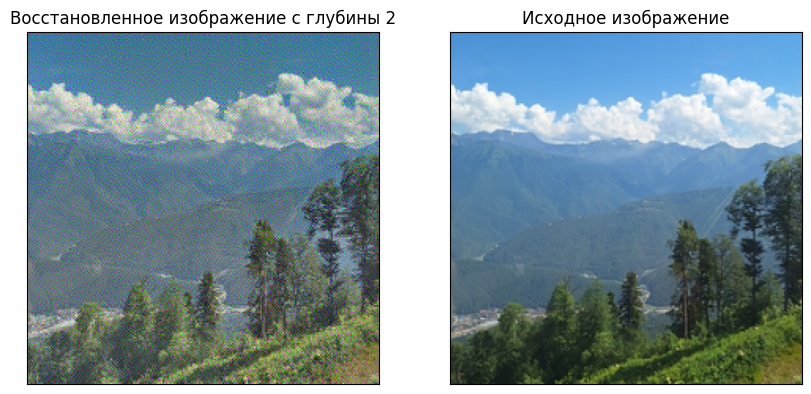

In [14]:
deep = 2
reconstruction_conv_2 = reconstruct_image(normalized_img, deep, 0, 0.1, 1000, device)

plot_reconstruction(reconstruction_conv_2, deep)

Здесь шуму прибавилось, содержание изображения все еще различимо. Идем дальше. Всего 5 пулингов, так что идем до глубины 4.

Шаг 20, loss = 50.41968536376953
Шаг 40, loss = 34.8212890625
Шаг 60, loss = 26.12935447692871
Шаг 80, loss = 20.69226837158203
Шаг 100, loss = 16.918292999267578
Шаг 120, loss = 14.234498023986816
Шаг 140, loss = 12.275400161743164
Шаг 160, loss = 10.775398254394531
Шаг 180, loss = 9.608663558959961
Шаг 200, loss = 8.678704261779785
Шаг 220, loss = 7.908070087432861
Шаг 240, loss = 7.267507076263428
Шаг 260, loss = 6.720736503601074
Шаг 280, loss = 6.263200759887695
Шаг 300, loss = 5.883730411529541
Шаг 320, loss = 5.553691387176514
Шаг 340, loss = 5.249673366546631
Шаг 360, loss = 4.968166828155518
Шаг 380, loss = 4.707723617553711
Шаг 400, loss = 4.475365161895752
Шаг 420, loss = 4.26634407043457
Шаг 440, loss = 4.08038330078125
Шаг 460, loss = 3.9084036350250244
Шаг 480, loss = 3.7490787506103516
Шаг 500, loss = 3.5997395515441895
Шаг 520, loss = 3.460008144378662
Шаг 540, loss = 3.3283870220184326
Шаг 560, loss = 3.203465700149536
Шаг 580, loss = 3.0851564407348633
Шаг 600, loss =

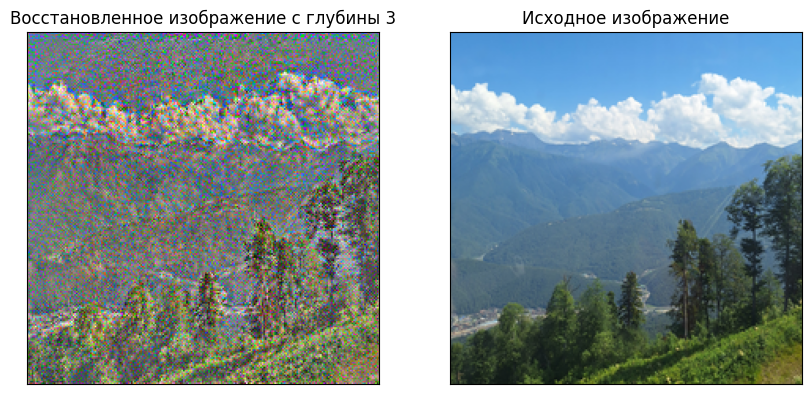

In [15]:
deep = 3
reconstruction_conv_3 = reconstruct_image(normalized_img, deep, 0, 0.01, 10000, device)

plot_reconstruction(reconstruction_conv_3, deep)

Шум очень заметен на получившейся картинке, при этом содержание исходного изображения сохранилось.

Шаг 20, loss = 11.489481925964355
Шаг 40, loss = 6.814878463745117
Шаг 60, loss = 4.102706432342529
Шаг 80, loss = 2.6260030269622803
Шаг 100, loss = 1.7486969232559204
Шаг 120, loss = 1.2946248054504395
Шаг 140, loss = 1.040376901626587
Шаг 160, loss = 0.876907467842102
Шаг 180, loss = 0.7548919916152954
Шаг 200, loss = 0.6625872254371643
Шаг 220, loss = 0.5918304324150085
Шаг 240, loss = 0.5337870121002197
Шаг 260, loss = 0.48717325925827026
Шаг 280, loss = 0.44860371947288513
Шаг 300, loss = 0.41413983702659607
Шаг 320, loss = 0.38424575328826904
Шаг 340, loss = 0.3576376438140869
Шаг 360, loss = 0.33346879482269287
Шаг 380, loss = 0.3118521273136139
Шаг 400, loss = 0.2931530475616455
Шаг 420, loss = 0.27609333395957947
Шаг 440, loss = 0.2602035403251648
Шаг 460, loss = 0.2464522272348404
Шаг 480, loss = 0.2338876724243164
Шаг 500, loss = 0.2228282243013382
Шаг 520, loss = 0.21258284151554108
Шаг 540, loss = 0.20308800041675568
Шаг 560, loss = 0.19430887699127197
Шаг 580, loss = 0.1

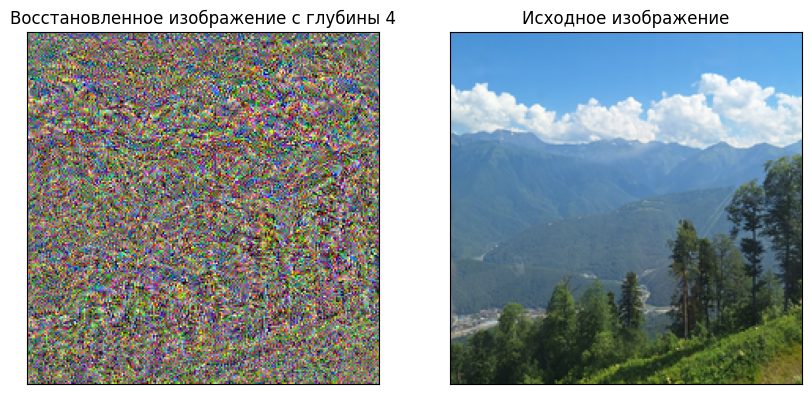

In [16]:
deep = 4
reconstruction_conv_4 = reconstruct_image(normalized_img, deep, 0, 0.01, 5000, device)

plot_reconstruction(reconstruction_conv_4, deep)

Увидеть что-то в полученном изображении в разы сложнее, оно полностью состоит из шума. Однако, можно увидеть среди этого шума силуэты основных объектов, например, высоких деревьев на переднем плане, облаков.

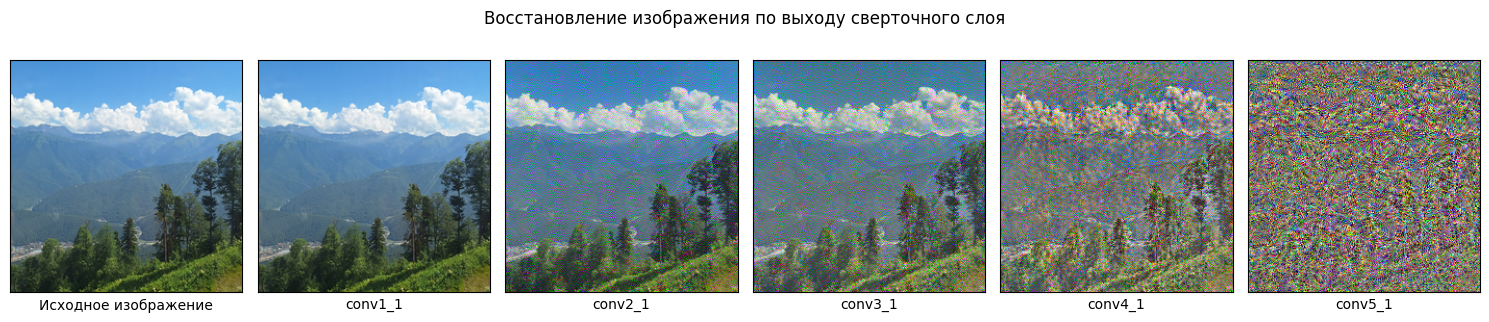

In [17]:
reconstructions = [normalized_img,
                   reconstruction_conv_0,
                   reconstruction_conv_1,
                   reconstruction_conv_2,
                   reconstruction_conv_3,
                   reconstruction_conv_4]

fig, axes = plt.subplots(1, 6, figsize=(15, 10))

for i in range(6):
    axes[i].imshow(denormalization(reconstructions[i]).permute(1, 2, 0).cpu())
    axes[i].set_xticks([])
    axes[i].set_yticks([])
    if i == 0:
        axes[i].set_xlabel('Исходное изображение')
    else:
        axes[i].set_xlabel(f'conv{i}_1')

plt.suptitle('Восстановление изображения по выходу сверточного слоя', y=0.65)
plt.tight_layout()
plt.show()

**Итоги:**

Метод градиентного спуска для шума с последующей прогонкой через слои сети для приближения к имеющимся выходам сверточного слоя дает результат, изображение восстанавливается в разной степени в зависимости от глубины слоя.

Получили, что из выходов верхних сверточных слоев (до глубины conv3_*) можно восстановить исходное изображение с большой точностью. С увеличением глубины восстанавливаемое изображение становится все более зашумленным в сравнении с исходным.

Этот опыт дает характеристику сверточных слоев, а именно позволяет понять, какую информацию они сохраняют с увеличением глубины. Из вида изображения, восстановленного по сверточному слою на самом глубоком уровне (до последнего пулинга), видно, что сеть оставляет от исходного изображения лишь силуэты главных элементов, забывая про цвет и мелкие детали. Это можно понять из того, что восстановленная картинка в целом представляет из себя шум, в котором можно рассмотреть части исходного изображения.

Полученный результат можно использовать в переносе стиля, ведь мы хотим сохранить в такой задаче именно смысловое содержание изображения - предметы и их расположения, формы.